In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sb
from sklearn import decomposition
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

gist_raw_url = "https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv"

try:
    dataset = pd.read_csv(gist_raw_url)
except Exception:
    dataset = pd.read_csv("iris.csv")

dataset.head()

Matplotlib is building the font cache; this may take a moment.


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [2]:
# 2) K-Medias sobre los datos originales sin transformaciones
# Tomamos las 4 columnas numéricas de medidas de la flor (sepal.length, sepal.width, petal.length, petal.width)
X_orig = dataset.iloc[:, [0, 1, 2, 3]].values
print("Dimensiones de X_orig:", X_orig.shape)
print(X_orig[:5])

Dimensiones de X_orig: (150, 4)
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


  File "C:\Users\emsb0\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


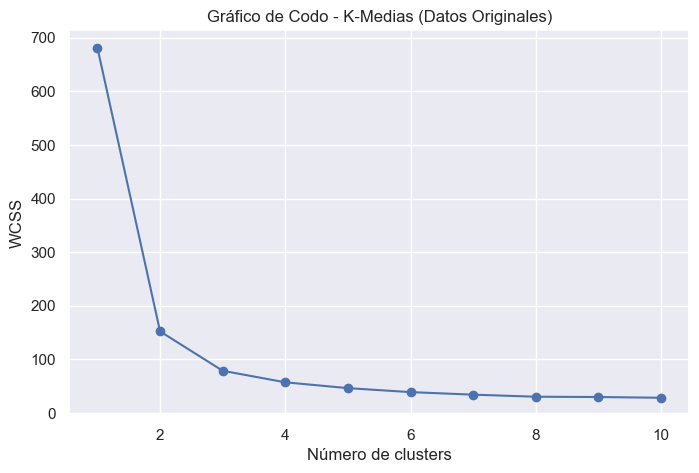

In [3]:
# Calcular WCSS (inercia) para k de 1 a 10 en los datos originales (gráfico de codo)
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    kmeans.fit(X_orig)
    wcss.append(kmeans.inertia_)

sb.set()
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Gráfico de Codo - K-Medias (Datos Originales)")
plt.xlabel("Número de clusters")
plt.ylabel("WCSS")
plt.show()

Score Silhouette; k = 2 : 0.6810
Score Silhouette; k = 3 : 0.5512
Score Silhouette; k = 4 : 0.4976
Score Silhouette; k = 5 : 0.4931
Score Silhouette; k = 6 : 0.3678
Score Silhouette; k = 7 : 0.3543
Score Silhouette; k = 8 : 0.3447
Score Silhouette; k = 9 : 0.3156
Score Silhouette; k = 10 : 0.3014


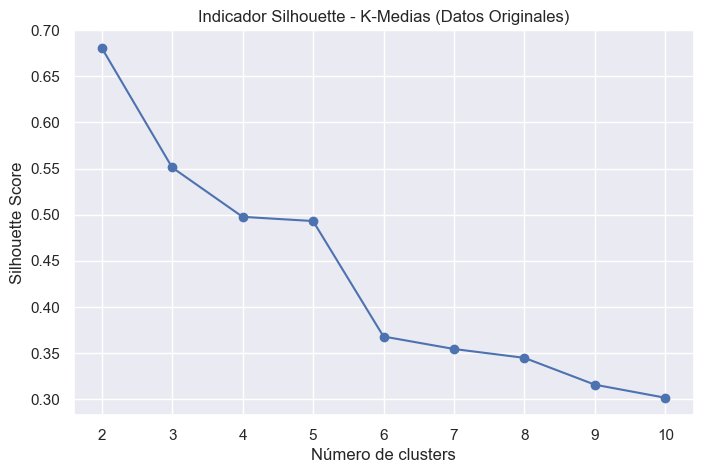

In [4]:
# Calcular el indicador Silhouette para k de 2 a 10 en los datos originales
sil_scores_orig = []
k_range_sil = range(2, 11)

for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    labels = kmeans.fit_predict(X_orig)
    score = silhouette_score(X_orig, labels, metric="euclidean")
    sil_scores_orig.append(score)
    print(f"Score Silhouette; k = {k} : {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_sil), sil_scores_orig, marker="o")
plt.title("Indicador Silhouette - K-Medias (Datos Originales)")
plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score")
plt.show()

In [5]:
# Ajustar K-Medias con k = 3 sobre los datos originales
kmeans_orig = KMeans(n_clusters=3, init="k-means++", random_state=42)
clusters_orig = kmeans_orig.fit_predict(X_orig)
print("Asignación de clusters (datos originales, k=3):")
print(clusters_orig)

Asignación de clusters (datos originales, k=3):
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


In [6]:
# 3) Transformación de los datos originales a 2 columnas mediante PCA
pca = decomposition.PCA(n_components=2)
X_pca = pca.fit_transform(X_orig)

print("Varianza explicada por componente:", np.round(pca.explained_variance_ratio_, 4))
print("Varianza total explicada (2 componentes):", round(sum(pca.explained_variance_ratio_), 4))
print("Dimensiones de X_pca:", X_pca.shape)
X_pca[:5]

Varianza explicada por componente: [0.9246 0.0531]
Varianza total explicada (2 componentes): 0.9777
Dimensiones de X_pca: (150, 2)


array([[-2.68412563,  0.31939725],
       [-2.71414169, -0.17700123],
       [-2.88899057, -0.14494943],
       [-2.74534286, -0.31829898],
       [-2.72871654,  0.32675451]])

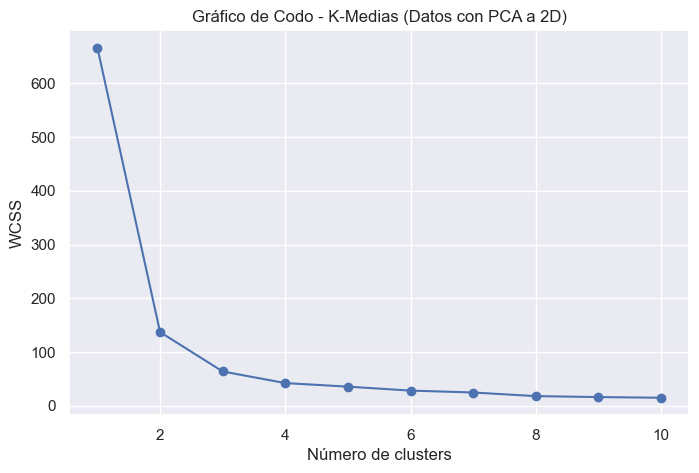

In [7]:
# Gráfico de codo (WCSS) sobre los datos reducidos a 2 dimensiones con PCA
wcss_pca = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    kmeans.fit(X_pca)
    wcss_pca.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_pca, marker="o")
plt.title("Gráfico de Codo - K-Medias (Datos con PCA a 2D)")
plt.xlabel("Número de clusters")
plt.ylabel("WCSS")
plt.show()

Score Silhouette (PCA); k = 2 : 0.7057
Score Silhouette (PCA); k = 3 : 0.5977
Score Silhouette (PCA); k = 4 : 0.5577
Score Silhouette (PCA); k = 5 : 0.5100
Score Silhouette (PCA); k = 6 : 0.4032
Score Silhouette (PCA); k = 7 : 0.3868
Score Silhouette (PCA); k = 8 : 0.4408
Score Silhouette (PCA); k = 9 : 0.4020
Score Silhouette (PCA); k = 10 : 0.4159


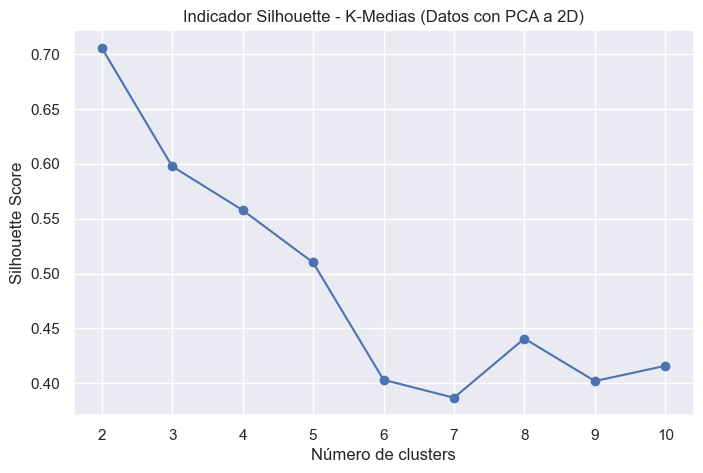

In [8]:
# Indicador Silhouette sobre los datos reducidos a 2 dimensiones con PCA
sil_scores_pca = []

for k in k_range_sil:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels, metric="euclidean")
    sil_scores_pca.append(score)
    print(f"Score Silhouette (PCA); k = {k} : {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_sil), sil_scores_pca, marker="o")
plt.title("Indicador Silhouette - K-Medias (Datos con PCA a 2D)")
plt.xlabel("Número de clusters")
plt.ylabel("Silhouette Score")
plt.show()

Asignación de clusters (PCA, k=3):
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


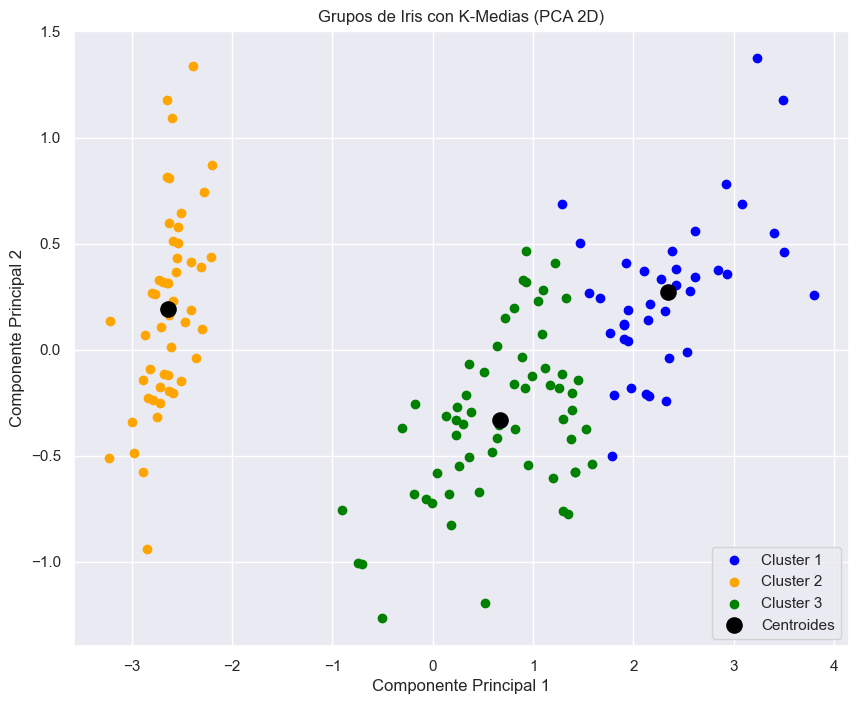

In [9]:
# Aplicar K-Medias con k = 3 sobre las 2 dimensiones de PCA y graficar los grupos
kmeans_pca = KMeans(n_clusters=3, init="k-means++", random_state=42)
cluster_values_pca = kmeans_pca.fit_predict(X_pca)
print("Asignación de clusters (PCA, k=3):")
print(cluster_values_pca)

plt.figure(figsize=(10, 8))
plt.scatter(X_pca[cluster_values_pca == 0, 0], X_pca[cluster_values_pca == 0, 1], c="blue", label="Cluster 1")
plt.scatter(X_pca[cluster_values_pca == 1, 0], X_pca[cluster_values_pca == 1, 1], c="orange", label="Cluster 2")
plt.scatter(X_pca[cluster_values_pca == 2, 0], X_pca[cluster_values_pca == 2, 1], c="green", label="Cluster 3")

plt.scatter(
    kmeans_pca.cluster_centers_[:, 0],
    kmeans_pca.cluster_centers_[:, 1],
    c="black",
    s=120,
    label="Centroides"
)

plt.title("Grupos de Iris con K-Medias (PCA 2D)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.show()

In [10]:
# 4) Comparación entre los resultados de K-Medias en datos originales (inciso 2) y con PCA (inciso 3)
print("Comparación de etiquetas (Original vs PCA) para k=3:")
print(pd.crosstab(
    pd.Series(clusters_orig, name="Datos Originales"),
    pd.Series(cluster_values_pca, name="PCA 2D")
))

print("\nComparación de clusters PCA vs variedad real:")
print(pd.crosstab(
    pd.Series(cluster_values_pca, name="Cluster PCA"),
    dataset.iloc[:, 4]
))

Comparación de etiquetas (Original vs PCA) para k=3:
PCA 2D             0   1   2
Datos Originales            
0                 39   0   0
1                  0  50   0
2                  0   0  61

Comparación de clusters PCA vs variedad real:
variety      Setosa  Versicolor  Virginica
Cluster PCA                               
0                 0           3         36
1                50           0          0
2                 0          47         14
